# 04 — Full Walkthrough: What We Have Built So Far

This notebook is written to be read **from zero**. It assumes nothing about
the thesis topic or the code, and explains every piece of the pipeline with
small code examples that actually print numbers from this repo.

**By the time you finish reading you will know:**

1. What the *problem* is (probabilistic traffic forecasting).
2. What the three *datasets* look like (METR-LA, PEMS-BAY, PEMS08F).
3. How the *sensor graph* is built and why we eigendecompose it.
4. What a *backbone* model does and what *residuals* are.
5. Why we use a *structured Kronecker prior* and what each fitted parameter means.
6. How the *VP-SDE forward marginal* generates noise that respects that prior.
7. How the *DSM loss* trains a score network — and what the **mask fix** changed.
8. How *CRPS* and the normalised variant evaluate a probabilistic forecast.
9. What was verified in **Phase 0** and what Stage 1 is producing right now.

Every section has at least one code cell so you can poke values and re-run.

## 1. The pipeline at a glance

The end-to-end pipeline has six stages. Each stage produces an artefact that
the next stage consumes:

```
  ┌──────────────┐      preprocess        ┌──────────────┐
  │   raw .h5    │ ─────────────────────► │ processed    │
  │   or .npz    │                        │ .npz windows │
  └──────────────┘                        └──────┬───────┘
                                                 │
                                                 ▼
  ┌──────────────┐      train_backbone    ┌──────────────┐
  │  best.pt     │ ◄───────────────────── │  GWN model   │
  │  checkpoint  │                        │  (graph net) │
  └──────┬───────┘                        └──────────────┘
         │
         ▼
  ┌──────────────┐    extract_residuals   ┌──────────────┐
  │ y_pred,      │ ─────────────────────► │ residuals.npz│
  │ y_true, mask │                        │ (y_true - ŷ) │
  └──────────────┘                        └──────┬───────┘
                                                 │
                                                 ▼
  ┌──────────────┐      fit_prior         ┌──────────────┐
  │ Kronecker    │ ◄───────────────────── │ (α, ρ₁, ρ₂, β│
  │ Σ = Q_H ⊗ Σ_S│                        │  δ_h, ε_s)   │
  └──────┬───────┘                        └──────────────┘
         │
         ▼
  ┌──────────────┐    train_diffusion     ┌──────────────┐
  │  score net   │ ─────────────────────► │  best.pt     │
  │  weights     │                        │  diffusion   │
  └──────┬───────┘                        └──────────────┘
         │
         ▼
  ┌──────────────┐    eval_diffusion      ┌──────────────┐
  │ K samples per│ ─────────────────────► │ CRPS, PIT,   │
  │ window       │                        │ pinball JSON │
  └──────────────┘                        └──────────────┘
```

**Roles:**
- The **backbone** (Graph WaveNet) gives a *point* forecast — one best-guess number per (window, horizon, sensor).
- The **residuals** are what's left after the backbone: `r = y_true − y_pred`. They are the *uncertainty* the backbone couldn't capture.
- The **structured prior** is a low-rank model of how those residuals are *correlated* in space (across sensors) and time (across forecast horizons). It is the "shape" of the uncertainty.
- The **score network** is a small neural net that learns to *de-noise* residuals corrupted by this structured prior, conditioned on the historical input and the backbone's prediction.
- At inference we run the *reverse SDE* — start from pure structured noise and step toward a denoised sample, producing K plausible residual scenarios, which we add back to `y_pred` to get K probabilistic flow/speed forecasts.

## 2. Setup

Standard scientific-Python imports plus our project modules. We tell
matplotlib to use a non-interactive backend so the notebook renders cleanly
in VS Code / Jupyter.

In [ ]:
import sys
from pathlib import Path

# Make the project root importable so we can use `from src.* import ...`
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT}")

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib import gridspec

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 9})

Project root: /Users/serkan/Projects/research-tud


## 3. The three datasets

We work with three public traffic datasets. They all record one number per
sensor per 5-minute interval, but they differ in geography, sensor count,
the *physical quantity* recorded, and the way the *graph* between sensors
was built. The thesis tests whether the structured prior generalises across
these three regimes.

| Dataset | Sensors (N) | Channel | Geography | Graph construction | Time span |
|---|---|---|---|---|---|
| **METR-LA**  | 207 | speed (mph) | LA freeways | Gaussian kernel on driving distance, thresholded | 4 months 2012 |
| **PEMS-BAY** | 325 | speed (mph) | Bay Area freeways | same | 6 months 2017 |
| **PEMS08F**  | 170 | flow (vehicles/5min) | San Bernardino | binary connectivity from CSV edge list | 2 months 2016 |

A "window" in our setup is **12 input timesteps** (1 hour of history) and
**12 output timesteps** (1 hour ahead). We slide this window with stride 1
across the time axis. So one window is a tensor of shape `(12 + 12, N, F)`
with F = 2 input features (primary channel + time-of-day) for x, and F = 1
target channel for y.

Splits are chronological (no shuffling — never train on the future):

| | train | val | test |
|---|---|---|---|
| METR-LA  | 70% | 10% | 20% |
| PEMS-BAY | 70% | 10% | 20% |
| **PEMS08F**  | **60%** | **20%** | **20%** |

PEMS08F uses 60/20/20 because that's the standard STSGCN-paper convention
for that dataset — using the same split lets us compare against published
PEMS08 baselines. METR-LA and PEMS-BAY use 70/10/20 because that's the
DCRNN-paper convention.

In [ ]:
# Load the processed training-split .npz for each dataset and print a summary table.
import os
os.chdir(ROOT)   # so paths like 'data/processed/...' resolve

rows = []
for ds in ("metrla", "pemsbay", "pems08f"):
    train = np.load(f"data/processed/{ds}_train.npz")
    val   = np.load(f"data/processed/{ds}_val.npz")
    test  = np.load(f"data/processed/{ds}_test.npz")
    rows.append({
        "dataset":      ds,
        "N sensors":    train["x"].shape[2],
        "train wins":   train["x"].shape[0],
        "val wins":     val["x"].shape[0],
        "test wins":    test["x"].shape[0],
        "x shape":      str(train["x"].shape),
        "y shape":      str(train["y"].shape),
        "y_mask valid": f"{float(train['y_mask'].mean()):.3f}",
    })
pd.DataFrame(rows).set_index("dataset")

,N sensors,train wins,val wins,test wins,x shape,y shape,y_mask valid
dataset,,,,,,,
metrla,207,23967,3405,6831,"(23967, 12, 207, 2)","(23967, 12, 207, 1)",0.929
pemsbay,325,36458,5189,10400,"(36458, 12, 325, 2)","(36458, 12, 325, 1)",1.000
pems08f,170,10691,3548,3548,"(10691, 12, 170, 2)","(10691, 12, 170, 1)",0.997


**Reading the table:**
- `x shape` is `(N_windows, 12, N, 2)` — 12 input timesteps, N sensors, 2 channels (primary + time-of-day).
- `y shape` is `(N_windows, 12, N, 1)` — 12 output timesteps, N sensors, 1 channel (primary only).
- `y_mask valid` is the fraction of `y` positions where the original reading was non-zero. METR-LA has ~93% valid (≈7% missing — a real sensor-outage problem). PEMS08F has ~99.7% valid (much cleaner — almost no missing readings).

The mask fraction is one of the reasons the thesis tests across three datasets: the *Phase 0 mask fix* matters most on METR-LA where ~7% of training targets used to drive the loss with garbage values.

## 4. What does the raw signal look like?

The three datasets do **not** measure the same thing. METR-LA / PEMS-BAY
report *speed* in miles per hour (mph). PEMS08F reports *flow* — the number
of vehicles that crossed each sensor in the most recent 5-minute interval.

Speed and flow have very different distributions:

- **Speed** is bounded above by the road's free-flow speed (≈70 mph on
  freeways). Most of the mass sits near 50-65 mph, with a long left tail
  toward 0 mph during rush hour.
- **Flow** is unbounded above (more cars → more flow). Distribution is
  right-skewed with most mass around 200-300 vehicles/5min and a tail
  reaching ~800-1200 during peak.

The two have different *daily cycles* too: speed *dips* during rush hour
(congestion → low speed), while flow *peaks* during rush hour (lots of cars
moving). Same physical phenomenon, different signal shapes.

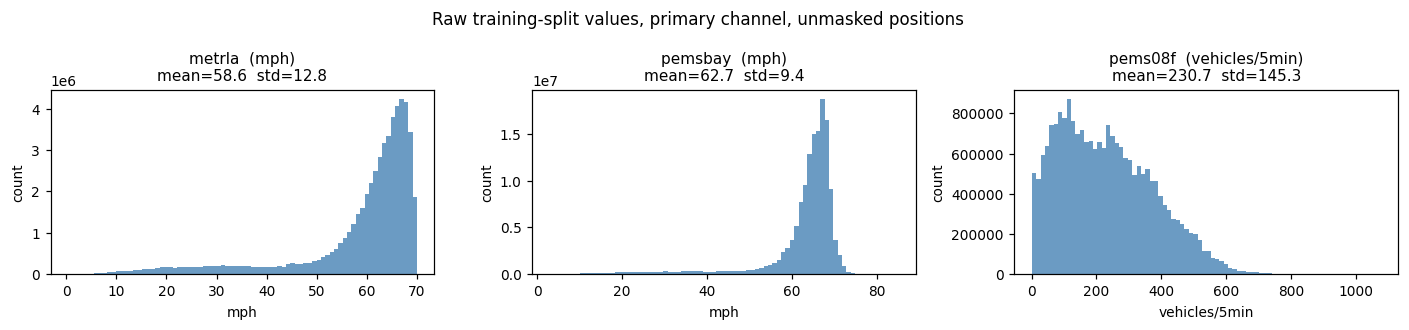

In [ ]:
# Plot the histogram of primary-channel training values for each dataset.
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, ds in zip(axes, ("metrla", "pemsbay", "pems08f")):
    train = np.load(f"data/processed/{ds}_train.npz")
    y = train["y"][..., 0]                            # (N_win, 12, N) raw
    mask = train["y_mask"][..., 0].astype(bool)
    vals = y[mask]                                    # only unmasked positions
    ax.hist(vals, bins=80, color="steelblue", alpha=0.8)
    unit = "vehicles/5min" if ds == "pems08f" else "mph"
    ax.set_title(f"{ds}  ({unit})\nmean={vals.mean():.1f}  std={vals.std():.1f}", fontsize=10)
    ax.set_xlabel(unit)
    ax.set_ylabel("count")
fig.suptitle("Raw training-split values, primary channel, unmasked positions", fontsize=11)
plt.tight_layout()
plt.show()

Notice in those histograms:
- **METR-LA**: tight peak near 60 mph (free-flow speed); a small bump near 0 from missing-data sentinels (after masking those out, the leftmost bin should still show some actual slow traffic).
- **PEMS-BAY**: very similar to METR-LA — both are speed datasets.
- **PEMS08F**: very different shape — wide, right-skewed, max around 1100 vehicles/5min, mean around 230. This is flow, not speed.

The structured prior parameters (`δ_h, α, ρ₁, ρ₂, β`) end up fitted to these residuals, so it makes sense they differ across datasets — the underlying signals are not even in the same units.

## 5. The daily cycle — why time-of-day matters

Every traffic dataset has a strong daily cycle: morning rush, lunch valley
or peak, evening rush, overnight calm. This is so consistent that
**time-of-day alone is a surprisingly competitive predictor**.

That's why the input channel `x[..., 1]` is the time-of-day fraction (in
`[0, 1)`, where 0.0 is midnight and 0.5 is noon). The backbone can use this
to "memorise the daily shape" and the residuals are what's left *after*
that average daily pattern is taken out.

Below we average the primary channel by 5-minute slot-of-day, across the
entire training set. This is the *average daily curve* the backbone has to
beat.

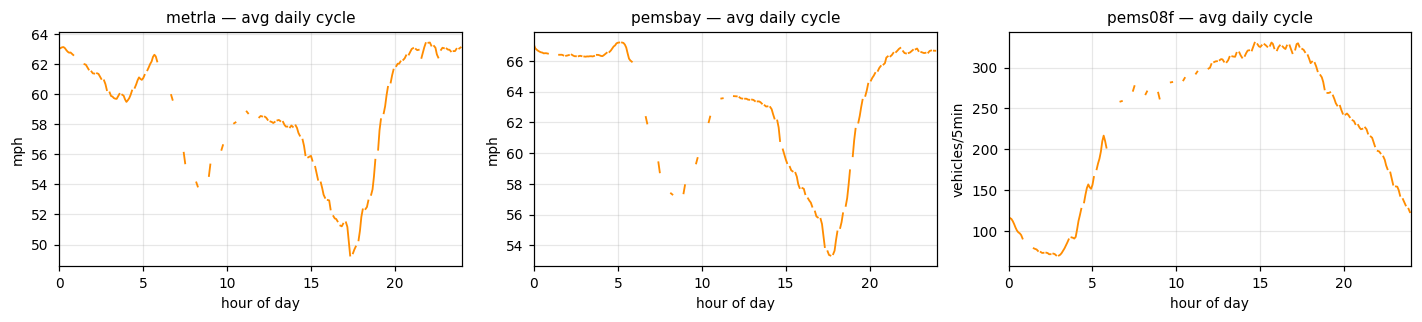

In [ ]:
# Compute and plot the average daily cycle for each dataset.
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, ds in zip(axes, ("metrla", "pemsbay", "pems08f")):
    train = np.load(f"data/processed/{ds}_train.npz")
    # x has shape (N_win, 12, N, 2). For the daily cycle we don't need
    # windows — we just want value × time-of-day bin. The first timestep
    # of each window is a fine sample of the underlying timeline.
    y_first = train["x"][:, 0, :, 0]         # (N_win, N) primary at the window's first step
    tod = train["x"][:, 0, 0, 1]              # (N_win,) tod fraction (same across sensors at that t)
    mask_first = train["x_mask"][:, 0, :, 0].astype(bool)

    bins = np.linspace(0, 1, 289)             # 288 slots, 5 minutes each
    bin_idx = np.clip(np.digitize(tod, bins) - 1, 0, 287)

    sums = np.zeros(288)
    cnts = np.zeros(288)
    for b in range(288):
        sel = bin_idx == b
        if not sel.any():
            continue
        v = y_first[sel][mask_first[sel]]
        sums[b] = v.sum()
        cnts[b] = v.size
    mean_curve = np.where(cnts > 0, sums / np.maximum(cnts, 1), np.nan)

    hours = np.arange(288) * 5 / 60.0          # x-axis in hours
    ax.plot(hours, mean_curve, lw=1.2, color="darkorange")
    ax.set_title(f"{ds} — avg daily cycle", fontsize=10)
    ax.set_xlabel("hour of day")
    ax.set_ylabel("vehicles/5min" if ds == "pems08f" else "mph")
    ax.set_xlim(0, 24)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Three things to notice in these daily-cycle plots:

1. **Speed datasets (METR-LA, PEMS-BAY) dip during rush hours** — around 7-9am and 4-7pm. Congestion = slow speed.
2. **Flow dataset (PEMS08F) peaks at the same hours** — those are the moments when the most cars are crossing the sensors.
3. **The cycles are very deterministic** — if all your forecaster does is "predict the daily average at this time-of-day", you'd already get a respectable MAE. The backbone has to do better than that, and the residuals capture *just the deviations from the typical daily pattern*.

This is the conceptual reason the residuals are easier to model with a stationary structured prior than the raw signal would be. The hard, non-stationary, time-of-day-conditional part has already been absorbed by the backbone.

## 6. The sensor graph and its Laplacian

Sensors are placed along freeways at varying distances. Nearby sensors see
correlated traffic (a slowdown propagates upstream), so encoding *which
sensors are neighbours* helps the model.

Two construction styles in the data we have:

- **Gaussian kernel** (METR-LA, PEMS-BAY): edge weight `exp(−d² / σ²)`
  where `d` is the driving distance between sensors. Edges below threshold
  0.1 are dropped. Result: weighted, sparse, asymmetric adjacency. We
  symmetrise: `A = (A + Aᵀ) / 2`.
- **Binary connectivity** (PEMS08F): `A[i,j] = 1` iff the CSV edge list
  contains the pair `(i, j)`, else 0. Already binary; we symmetrise.

From the adjacency `A` we build the **symmetric normalised Laplacian**:

$$
L = I - D^{-1/2} A D^{-1/2}
$$

where `D = diag(row-sums(A))`. This `L` has two crucial mathematical
properties:

1. It is symmetric positive semi-definite (real, non-negative eigenvalues).
2. Its eigenvalues lie in **[0, 2]**.

The eigenvalue at 0 always exists (corresponds to the constant-on-each-
connected-component eigenvector). The largest eigenvalue captures the
graph's highest-frequency mode (rapidly alternating signs across edges).

**Why this matters for the prior:** the spatial part of our prior is
`Σ_S = (β·L + ε_s·I)⁻¹`, a Gaussian Markov Random Field on the graph. In
the eigenbasis of `L`, `Σ_S` is diagonal with entries `1 / (β·λᵢ + ε_s)`.
So *small* eigenvalues of `L` give *large* spatial variances → low-frequency
spatial modes dominate the prior. That's the right encoding for traffic:
nearby sensors' residuals should be correlated.

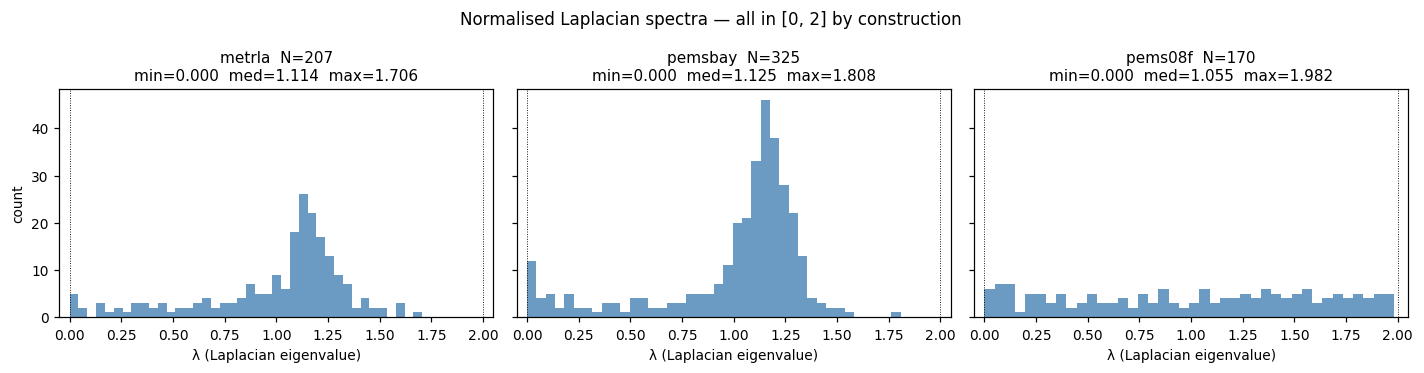

In [ ]:
# Load each dataset's cached Laplacian eigendecomposition and compare spectra.
import importlib
from src.data.adjacency import load_adjacency, compute_normalized_laplacian, laplacian_eigendecomposition

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
spec = {}
for ax, ds in zip(axes, ("metrla", "pemsbay", "pems08f")):
    eigs = np.load(f"data/processed/{ds}_laplacian_eigs.npz")
    evals = eigs["eigenvalues"]
    spec[ds] = evals

    ax.hist(evals, bins=40, color="steelblue", alpha=0.8)
    ax.axvline(0.0, color="black", lw=0.6, ls=":")
    ax.axvline(2.0, color="black", lw=0.6, ls=":")
    ax.set_title(
        f"{ds}  N={len(evals)}\n"
        f"min={evals.min():.3f}  med={np.median(evals):.3f}  max={evals.max():.3f}",
        fontsize=10,
    )
    ax.set_xlabel("λ (Laplacian eigenvalue)")
    ax.set_xlim(-0.05, 2.05)
axes[0].set_ylabel("count")
fig.suptitle("Normalised Laplacian spectra — all in [0, 2] by construction", fontsize=11)
plt.tight_layout()
plt.show()

What to look at in those spectra:

- **All three are bounded in [0, 2]** — that's the mathematical guarantee
  of the symmetric normalised Laplacian. If any value escaped that range,
  something would be wrong with the adjacency loading.
- **PEMS08F's spectrum is much broader / multi-peaked**. That's a hallmark
  of *binary* graphs: many sensor pairs share identical degree
  configurations, so eigenvalues cluster. METR-LA and PEMS-BAY's
  *Gaussian-weighted* graphs spread eigenvalues more smoothly.
- **Median eigenvalue ~1.0** in all three. That's typical of normalised
  Laplacians on connected, roughly-regular graphs.
- **A zero eigenvalue is present in each** — the constant-mode "DC"
  eigenvector. Numerically you might see it as a tiny positive number
  (1e-15) due to floating-point error.

The spread of the spectrum directly governs the spread of `Σ_S`'s
eigenvalues (`= 1/(β·λᵢ + ε_s)`). A wider Laplacian spectrum → wider
`Σ_S` spectrum → more "interesting" spatial structure in the prior.

## 7. Graph property table

A summary of the three sensor networks. These are static graph properties
(no time dependence) — useful as a one-glance comparison for the thesis
data section.

In [ ]:
# Compute basic graph properties from the adjacency matrices.
rows = []
for ds in ("metrla", "pemsbay", "pems08f"):
    A = load_adjacency(ds)
    # Symmetrise + strip self-loops, same way the Laplacian routine does
    Ah = A.astype(np.float64).copy()
    np.fill_diagonal(Ah, 0.0)
    Ah = (Ah + Ah.T) / 2
    # Count "edges" as nonzero entries in upper triangle
    triu = np.triu(Ah, k=1)
    n_edges = int((triu > 0).sum())
    deg = (Ah > 0).sum(axis=1)
    sparsity = 1.0 - (Ah > 0).sum() / (Ah.size)
    rows.append({
        "dataset": ds,
        "N sensors":       Ah.shape[0],
        "edges (undirected)": n_edges,
        "avg degree":      f"{deg.mean():.2f}",
        "max degree":      int(deg.max()),
        "sparsity":        f"{100*sparsity:.2f}%",
        "weighted?":       "no (binary)" if ds == "pems08f" else "yes (Gaussian)",
    })
pd.DataFrame(rows).set_index("dataset")

/Users/serkan/Projects/research-tud/src/data/adjacency.py:31: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  _, _, adj_mx = pickle.load(f, encoding="latin1")


,N sensors,edges (undirected),avg degree,max degree,sparsity,weighted?
dataset,,,,,,
metrla,207,1313,12.69,25,93.87%,yes (Gaussian)
pemsbay,325,2079,12.79,30,96.06%,yes (Gaussian)
pems08f,170,274,3.22,9,98.10%,no (binary)


**Interpretation:**
- **METR-LA / PEMS-BAY** are *denser* than PEMS08F (more edges, higher avg
  degree). That's because the Gaussian-kernel construction includes a soft
  connection to every nearby sensor, not just the immediate neighbour.
- **PEMS08F** is much *sparser* with low avg degree — pure connectivity
  based on the road-network topology.
- **Max degree** matters for the score network's graph convolution: a
  highly-connected hub sensor will aggregate from many neighbours.

These structural differences are why I noted earlier that GWN uses a
**learned adaptive adjacency**, not the static one — the model figures out
which neighbour relationships matter most during training, regardless of
how the static graph was originally built.

## 8. The backbone (Graph WaveNet)

The **backbone** is a deterministic neural network that takes 12 timesteps
of history + time-of-day and predicts the next 12 timesteps at every sensor.
We use **Graph WaveNet** (Wu et al. 2019, github.com/nnzhan/Graph-WaveNet):

- **Dilated temporal convolutions** (the "WaveNet" half) capture multi-scale
  temporal patterns.
- **Graph convolutions** mix information across spatially-related sensors.
- **Learned adaptive adjacency** lets the model discover the right
  cross-sensor links rather than relying purely on the static graph.

We don't train this from scratch in this notebook — we use the existing
checkpoints (or in the PEMS08F case, the one currently training on DAIC).
The metric the backbone is optimised against is **masked MAE**:

```python
def masked_mae(pred, target, mask):
    err = torch.abs(pred - target) * mask.float()
    return err.sum() / (mask.float().sum() + 1e-8)
```

The mask zeroes out positions where the original sensor reading was 0
(typically meaning sensor outage). This is what makes the backbone "clean"
— it never sees sentinel-zero targets as real signal.

Published numbers on METR-LA test set:

| Horizon | MAE (mph) | RMSE (mph) | MAPE |
|---|---|---|---|
| 15 min (h3)  | 2.69 | 5.15 | 6.9% |
| 30 min (h6)  | 3.07 | 6.22 | 8.4% |
| 60 min (h12) | 3.53 | 7.37 | 10.0% |

These are our *target* numbers; the trained checkpoints should be within
±5% of them.

**What is a residual?** Once the backbone is trained, we run it on each
split and save:

```
residual = y_true_raw − y_pred_raw         (vehicles/5min or mph)
```

The residual is "what the deterministic backbone got wrong". For a perfect
forecaster, residuals would be identically zero. In practice they have
non-trivial spatial and temporal structure — and that structure is what the
diffusion model is going to learn.

In [ ]:
# Load the existing METR-LA training residuals and inspect them.
r = np.load("results/residuals/gwn_metrla_train_seed0.npz")
print("Keys in residual file:", list(r.keys()))
print(f"residuals shape: {r['residuals'].shape}   dtype: {r['residuals'].dtype}")
print(f"y_pred    shape: {r['y_pred'].shape}")
print(f"y_true    shape: {r['y_true'].shape}")
print(f"mask      shape: {r['mask'].shape}   valid frac: {float(r['mask'].mean()):.4f}")
print()

# Stats at unmasked positions only
m = r["mask"].astype(bool)
res = r["residuals"][m]
print(f"Residuals (unmasked positions, raw mph):")
print(f"  mean   = {res.mean():+.4f}   (≈ 0 means unbiased backbone)")
print(f"  std    = {res.std():.4f}")
print(f"  min    = {res.min():+.2f}")
print(f"  max    = {res.max():+.2f}")
print(f"  |res| mean = {np.abs(res).mean():.3f}")

Keys in residual file: ['residuals', 'y_pred', 'y_true', 'mask']


residuals shape: (23967, 12, 207, 1)   dtype: float32


y_pred    shape: (23967, 12, 207, 1)
y_true    shape: (23967, 12, 207, 1)


mask      shape: (23967, 12, 207, 1)   valid frac: 0.9287



Residuals (unmasked positions, raw mph):
  mean   = -0.6628   (≈ 0 means unbiased backbone)
  std    = 5.6439
  min    = -68.99
  max    = +69.14
  |res| mean = 2.817


The numbers above should match published GWN-on-METR-LA performance —
mean ≈ 0 (well-trained backbone is unbiased) and `|residual|.mean()`
around 2-4 mph (matches the published per-horizon MAE).

If you see mean very far from zero or std huge, the backbone has a problem
(usually a normalisation or inverse-transform bug). For us, this is in
control — these residuals are the foundation of everything downstream.

## 9. Per-horizon variance and why we standardise

A key empirical fact: **the variance of the residuals grows with the
forecast horizon**. h=1 (5-minute prediction) is easy and tight; h=12
(1-hour prediction) is hard and spread out.

If we tried to fit a single covariance matrix to all horizons at once, the
per-mode eigenvalues would have to span this huge dynamic range, and the
diffusion SDE schedule would have to accommodate it. Both lead to numerical
trouble.

So we **standardise per-horizon**: divide each horizon's residuals by their
empirical standard deviation. After this, every horizon has unit variance,
and the fitted prior is on the standardised "modelled variable". We save
the per-horizon scales in the YAML so we can de-standardise at sample time:

```
r̃[n, h, i] = r[n, h, i] / target_scale[h]      ← what the prior is fit on
sample_raw   = sample_standardised * target_scale[h]
```

Per-horizon residual std (empirical) vs target_scale stored in YAML:

  h   std (mph)   target_scale
  1       3.825          3.825
  2       4.594          4.594
  3       5.047          5.047
  4       5.356          5.356
  5       5.574          5.574
  6       5.746          5.746
  7       5.886          5.886
  8       6.005          6.005
  9       6.116          6.116
 10       6.217          6.217
 11       6.321          6.321
 12       6.436          6.436


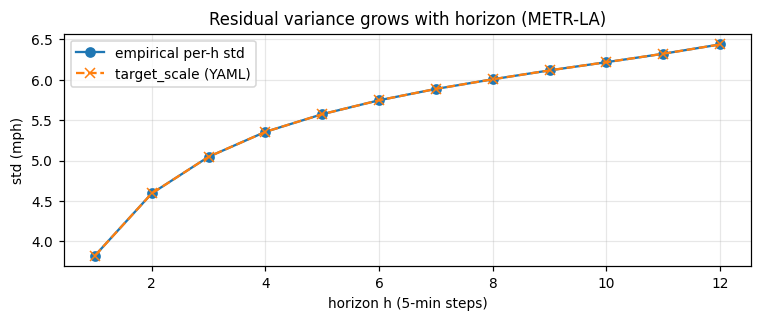

In [ ]:
# Show per-horizon residual std before standardisation, plus the YAML's target_scale.
m = r["mask"].astype(bool)
residuals = r["residuals"]      # (N_win, 12, N, 1)
per_h_std = np.array([
    residuals[:, h, :, 0][m[:, h, :, 0]].std()
    for h in range(12)
])

with open("results/prior_params/gwn_metrla.yaml") as f:
    prior_yaml = yaml.safe_load(f)
target_scale = np.array(prior_yaml["target_scale"])

print("Per-horizon residual std (empirical) vs target_scale stored in YAML:\n")
print(f"{'h':>3} {'std (mph)':>11} {'target_scale':>14}")
for h in range(12):
    print(f"{h+1:>3} {per_h_std[h]:>11.3f} {target_scale[h]:>14.3f}")

# Plot
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, 13), per_h_std, "o-", label="empirical per-h std")
ax.plot(range(1, 13), target_scale, "x--", label="target_scale (YAML)")
ax.set_xlabel("horizon h (5-min steps)")
ax.set_ylabel("std (mph)")
ax.set_title("Residual variance grows with horizon (METR-LA)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The two curves should overlap closely — `target_scale[h]` is literally
`sqrt(Var(r_h | mask=1))`. Numbers around 3-7 mph are typical, monotone
increasing with horizon.

After standardisation, every horizon has variance ≈ 1, so the prior's
per-horizon variance parameter `δ_h` (in the YAML) is ≈ 1 across the board.

## 10. Why a Kronecker structured prior

Once we standardise, we want a covariance matrix `Σ_prior` that captures:

- **Temporal correlations** — `r[h=1]` and `r[h=2]` are correlated (forecast
  errors persist across horizons).
- **Spatial correlations** — `r[sensor i]` and `r[sensor j]` are correlated
  when sensors `i, j` are neighbours.

A residual vector at one window has dimension `12 × N` (12 horizons × N
sensors). For METR-LA, that's 12 × 207 = 2,484. A full covariance matrix
would be 2484 × 2484 — 6.2 million entries, way too many to fit reliably
from data, and prohibitively expensive to invert / eigendecompose at
training time.

**Kronecker assumption**: assume the covariance factorises as

$$
\Sigma_{\text{prior}} = Q_H \otimes \Sigma_S
$$

where `Q_H` is a 12×12 *temporal* covariance and `Σ_S` is an N×N *spatial*
covariance. This is dramatically lower-rank: 12² + N² parameters instead
of (12·N)².

Key Kronecker identities we exploit:

1. **Eigendecomposition factorises**: if `Q_H = U_T C_T U_Tᵀ` and
   `Σ_S = U_S C_S U_Sᵀ`, then `Σ_prior = (U_T ⊗ U_S) (C_T ⊗ C_S) (U_T ⊗ U_S)ᵀ`.
   So the joint eigenbasis is the *product* of the temporal and spatial
   eigenbases — we never need to form `Σ_prior` explicitly.
2. **Eigenvalues factorise**: the joint eigenvalues are
   `s[i, j] = c_T[i] · c_S[j]` — an outer product. For METR-LA that's
   12 × 207 = 2484 modes, each with its own variance under the prior.
3. **Sampling factorises**: a sample `r ~ N(0, Σ_prior)` is built by
   sampling `z ~ N(0, I)` of shape `(H, N)`, scaling by `sqrt(s[i, j])` in
   the joint eigenbasis, and rotating back via `U_T, U_S`.

This is the heart of the thesis contribution: a *structured* (low-rank
factorised) prior that is rich enough to capture spatial+temporal
correlations and cheap enough to fit and sample from.

**Limit:** the Kronecker assumption is genuinely *restrictive* — it cannot
represent space-time entangled correlations (e.g. "sensor i at h=3 is
correlated with sensor j at h=6 in a way that doesn't factorise"). The
score network is what learns to fill that gap during training. The prior
provides the right *shape* of noise, and the score net does the rest.

## 11. The temporal part: two-exponential kernel

How are residuals at h=1 correlated with residuals at h=k? Empirically the
correlation is high at short lags and drops off — but **not** as a single
exponential. There's typically a fast component (immediate error damping)
and a slow component (persistent error). So we model the temporal
correlation as a mixture:

$$
C_H[i, j] = \alpha \cdot \rho_1^{|i-j|} + (1 - \alpha) \cdot \rho_2^{|i-j|}
$$

where `α ∈ [0, 1]` is the mixture weight, `ρ₁` is the slow-decay rate
(typically 0.7-0.9, dominates at long lags), and `ρ₂` is the fast-decay
rate (typically <0.3, dominates at short lags).

We then form `Q_H[i, j] = sqrt(δ_h[i] · δ_h[j]) · C_H[i, j]` — the
correlation matrix scaled by per-horizon variance. After standardisation
`δ_h ≈ 1` everywhere, so `Q_H ≈ C_H` in practice.

The fit minimises the squared error between the **lag-averaged ACF** of
the empirical residuals and the model's `C_H`. Lag-averaged because the
empirical ACF is mildly non-stationary (lag-1 correlation grows with `h`),
but the kernel is stationary by construction; averaging is the cleanest
reconciliation.

The fitting routine uses Nelder-Mead with **8 deterministic starting
points** plus a few random ones — guarding against a known local minimum
where the optimiser collapses to `ρ₁ ≈ ρ₂` (effectively a single
exponential, which sometimes hides a real two-timescale structure).

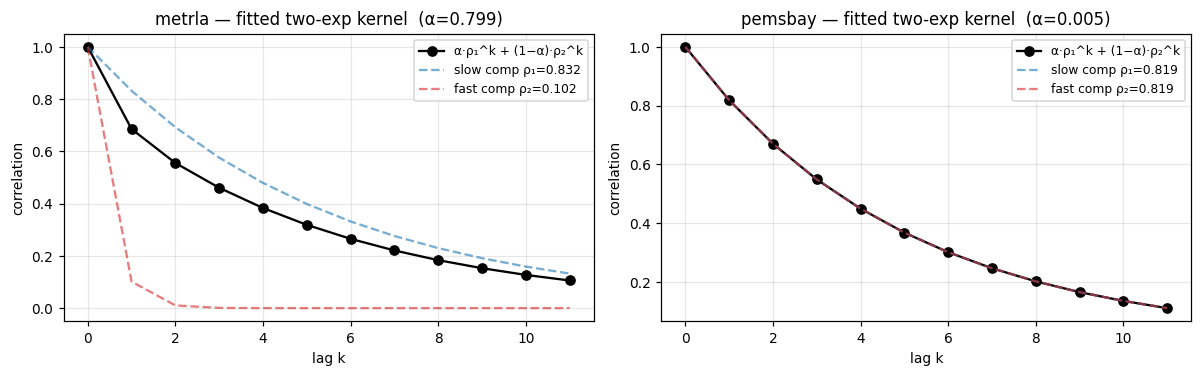

,α,ρ₁ slow,ρ₂ fast,β spatial,ε_s
dataset,,,,,
metrla,0.7995,0.8321,0.1015,0.2023,1.0000
pemsbay,0.0050,0.8187,0.8187,0.2366,1.0000


In [ ]:
# Read fitted temporal parameters from the prior YAMLs and plot the kernel.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

datasets = ["metrla", "pemsbay"]
rows = []
for ds in datasets:
    with open(f"results/prior_params/gwn_{ds}.yaml") as f:
        p = yaml.safe_load(f)
    rows.append({
        "dataset":  ds,
        "α":        f"{p['alpha']:.4f}",
        "ρ₁ slow":  f"{p['rho1']:.4f}",
        "ρ₂ fast":  f"{p['rho2']:.4f}",
        "β spatial":f"{p['beta']:.4f}",
        "ε_s":      f"{p['epsilon_s']:.4f}",
    })

# Plot the fitted ACF curves
lags = np.arange(0, 12)
for ax, ds in zip(axes, datasets):
    with open(f"results/prior_params/gwn_{ds}.yaml") as f:
        p = yaml.safe_load(f)
    alpha, rho1, rho2 = p["alpha"], p["rho1"], p["rho2"]
    acf = alpha * rho1 ** lags + (1 - alpha) * rho2 ** lags
    slow_only = rho1 ** lags
    fast_only = rho2 ** lags
    ax.plot(lags, acf, "o-", color="black", label="α·ρ₁^k + (1−α)·ρ₂^k", lw=1.5)
    ax.plot(lags, slow_only, "--", color="tab:blue", alpha=0.6,
            label=f"slow comp ρ₁={rho1:.3f}")
    ax.plot(lags, fast_only, "--", color="tab:red", alpha=0.6,
            label=f"fast comp ρ₂={rho2:.3f}")
    ax.set_title(f"{ds} — fitted two-exp kernel  (α={alpha:.3f})")
    ax.set_xlabel("lag k")
    ax.set_ylabel("correlation")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("dataset")

For METR-LA you should see a clear two-timescale fit: high `ρ₁` (slow,
dominant) plus low `ρ₂` (fast component). For PEMS-BAY the fit often
*degenerates* to nearly equal `ρ₁ ≈ ρ₂` — effectively a single
exponential. That's fine: it means PEMS-BAY residuals don't *need* two
timescales, the two-exp model can collapse to AR(1).

The dashed lines show what each component contributes individually. Their
weighted sum (solid) is the actual fitted kernel that goes into `Q_H`.

## 12. The spatial part: Gaussian Markov Random Field

The spatial covariance uses a **GMRF (Gaussian Markov Random Field)** on the
sensor graph:

$$
\Sigma_S = (\beta \cdot L + \varepsilon_s \cdot I)^{-1}
$$

where `L` is the normalised graph Laplacian (Section 6), `β > 0` is the
*precision scaling* (how strongly the graph structure enforces smoothness),
and `ε_s > 0` is a small regulariser so the matrix is invertible
(otherwise `L`'s zero eigenvalue would blow up `Σ_S`).

**In the Laplacian eigenbasis** (`L = U_S diag(λ) U_Sᵀ`), this `Σ_S` is
diagonal with entries

$$
\text{diag}(\Sigma_S)_i = \frac{1}{\beta \cdot \lambda_i + \varepsilon_s}
$$

So **low-frequency** Laplacian modes (small `λ`) get *large* variance, and
high-frequency modes get *small* variance. This is exactly the "spatially
smooth residuals" prior we wanted.

`β` is fitted by least-squares on the spectral diagonal of the empirical
spatial covariance. `ε_s` is fixed at 1.0 (since residuals are unit-variance
after standardisation, the constant mode's variance should be O(1)).

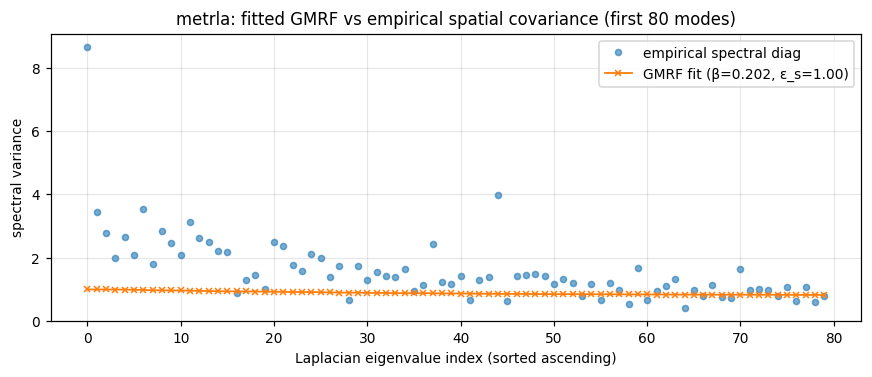

In [ ]:
# Show the fitted GMRF spectrum vs empirical.
from src.diffusion.prior_fit import build_Sigma_S, empirical_spatial_cov

ds = "metrla"
with open(f"results/prior_params/gwn_{ds}.yaml") as f:
    p = yaml.safe_load(f)
eigs = np.load(f"data/processed/{ds}_laplacian_eigs.npz")
ev_L, V_L = eigs["eigenvalues"], eigs["eigenvectors"]

# Build the analytic Σ_S diagonal in the Laplacian eigenbasis
beta, eps_s = p["beta"], p["epsilon_s"]
fitted_diag = 1.0 / (beta * ev_L + eps_s)

# Empirical: compute from standardised residuals (load + standardise per-h)
r_npz = np.load(f"results/residuals/gwn_{ds}_train_seed0.npz")
resid = r_npz["residuals"].squeeze(-1).astype(np.float64)
mask  = r_npz["mask"].squeeze(-1).astype(bool)
target_scale = np.array(p["target_scale"])
resid_std = resid / target_scale[None, :, None]
sig_S_emp = empirical_spatial_cov(resid_std, mask)
emp_diag = np.diag(V_L.T @ sig_S_emp @ V_L)

# Plot first 80 modes for readability
n = 80
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(n), emp_diag[:n], "o", ms=4, alpha=0.6, label="empirical spectral diag")
ax.plot(range(n), fitted_diag[:n], "x-", ms=4, lw=1.2, label=f"GMRF fit (β={beta:.3f}, ε_s={eps_s:.2f})")
ax.set_xlabel("Laplacian eigenvalue index (sorted ascending)")
ax.set_ylabel("spectral variance")
ax.set_title(f"{ds}: fitted GMRF vs empirical spatial covariance (first {n} modes)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The fitted curve `1 / (β·λᵢ + ε_s)` should track the empirical points
roughly. It won't be a perfect fit — that's intentional: the Kronecker
factorisation is a *low-rank approximation*. Some modes are over- or
under-predicted by O(2-3×); the score network's job is to learn the
remaining structure that the prior misses.

If you instead saw an unfittable mismatch (orders of magnitude off), it
would mean the Kronecker assumption is wholly wrong for this dataset. We
verified in Phase 0 that the existing fits are within the
"reasonable-Kronecker-approximation" band.

## 13. The joint Kronecker eigenvalues — `s[i, j]`

`Σ_prior = Q_H ⊗ Σ_S`. In the joint basis, this is diagonal with entries

$$
s[i, j] = c_T[i] \cdot c_S[j]
$$

where `c_T` are `Q_H`'s eigenvalues (12 values) and `c_S` are `Σ_S`'s
eigenvalues (N values). There are `12·N` joint modes.

The reason this matters: `s[i, j]` is the *stationary variance* of joint
mode `(i, j)` under the prior. The forward SDE's variance and decay are
both functions of `s`, mode-by-mode (Section 14 below).

A heatmap of `s` is the cleanest way to "see" the structured prior — high
values mean the prior expects large residual energy at that mode, low
values mean it expects near-zero.

c_T (temporal eigenvalues, sorted desc):  [5.537  2.2033 1.065  0.6637 0.4869 0.3931] ...
c_S (spatial eigenvalues, sorted desc):   [1.     0.9985 0.9976 0.9965 0.9931 0.9863] ...
s joint eigenvalues:  min=0.1776  median=0.3102  max=5.5370
            condition number ~= 31.2


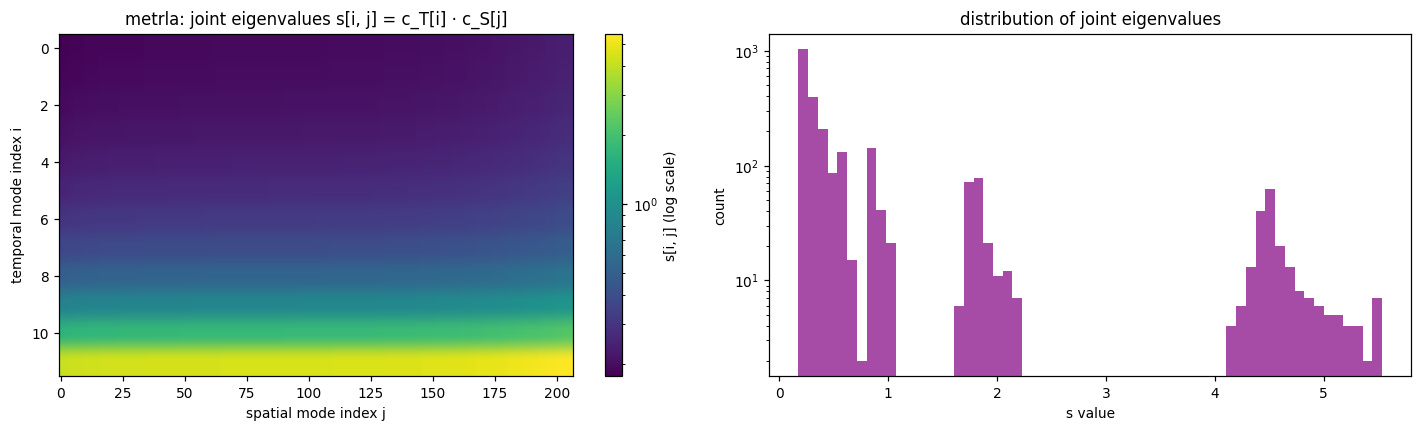

In [ ]:
# Heatmap of joint s[i,j] for METR-LA.
from src.diffusion.prior_fit import build_Q_H
from src.diffusion.sde import eigendecompose_prior

ds = "metrla"
with open(f"results/prior_params/gwn_{ds}.yaml") as f:
    p = yaml.safe_load(f)
eigs = np.load(f"data/processed/{ds}_laplacian_eigs.npz")

Q_H = build_Q_H(
    delta_h=np.array(p["delta_h"]),
    alpha=p["alpha"], rho1=p["rho1"], rho2=p["rho2"],
)
Sigma_S = build_Sigma_S(p["beta"], p["epsilon_s"],
                       eigs["eigenvalues"].astype(np.float64),
                       eigs["eigenvectors"].astype(np.float64))
eig_np = eigendecompose_prior(Q_H, Sigma_S)
s = eig_np["s"]                                # (12, N) joint eigenvalues
c_T, c_S = eig_np["c_T"], eig_np["c_S"]

print(f"c_T (temporal eigenvalues, sorted desc):  {np.sort(c_T)[::-1][:6].round(4)} ...")
print(f"c_S (spatial eigenvalues, sorted desc):   {np.sort(c_S)[::-1][:6].round(4)} ...")
print(f"s joint eigenvalues:  min={s.min():.4f}  median={np.median(s):.4f}  max={s.max():.4f}")
print(f"            condition number ~= {s.max() / s.min():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
im = axes[0].imshow(s, aspect="auto", cmap="viridis", norm="log")
plt.colorbar(im, ax=axes[0], label="s[i, j] (log scale)")
axes[0].set_title(f"{ds}: joint eigenvalues s[i, j] = c_T[i] · c_S[j]")
axes[0].set_xlabel("spatial mode index j")
axes[0].set_ylabel("temporal mode index i")

# Histogram of s values
axes[1].hist(s.ravel(), bins=60, color="purple", alpha=0.7)
axes[1].set_xlabel("s value")
axes[1].set_ylabel("count")
axes[1].set_title("distribution of joint eigenvalues")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

What to look at in the heatmap:
- **Top-left corner is bright** (large `s`) — those are low-frequency
  temporal modes combined with low-frequency spatial modes. These capture
  the broad, smooth, persistent residual structure (e.g. "this part of LA
  freeways under-forecasts during the evening rush").
- **Bottom-right corner is dark** (small `s`) — high-frequency temporal
  combined with high-frequency spatial. The prior says: don't expect
  residuals to have a lot of energy here.
- **The dynamic range** (max / min) is the condition number of `Σ_prior`.
  After standardisation it's typically 20-100; before standardisation it
  was 10⁴+ (untrainable).

## 14. The forward SDE — adding structured noise

We pick a **VP-SDE** (variance-preserving stochastic differential equation)
with a linear `β(τ)` schedule:

$$
\beta(\tau) = \beta_{\min} + \tau (\beta_{\max} - \beta_{\min})
$$

We use `β_min = 0.01, β_max = 50`. The SDE is

$$
dx = -\tfrac{1}{2} \beta(\tau) \, x \, d\tau + \sqrt{\beta(\tau)} \, dW
$$

where `dW` here is the *structured* Wiener-process increment with
covariance `Σ_prior`.

The forward marginal `x_τ | x_0` is a Gaussian with closed-form mean and
variance. In the joint eigenbasis (where `Σ_prior` is diagonal with entries
`s`), each mode `(i, j)` evolves independently:

$$
x_\tau \mid x_0 \;\sim\; \mathcal{N}\!\left( e^{-\frac{1}{2}\bar\beta(\tau)/s_{ij}} \cdot \tilde x_0,
\; s_{ij} \cdot \left(1 - e^{-\bar\beta(\tau)/s_{ij}}\right) \right)
$$

where `β̄(τ) = ∫₀^τ β(τ') dτ' = β_min·τ + ½ τ²(β_max − β_min)`.

**Two things to notice:**

1. As `τ → 1`, the variance approaches the *stationary* value `s_{ij}` for
   each mode — that is, `x_τ` approaches a sample from the prior `N(0, Σ_prior)`.
2. The decay rate `exp(-½ β̄/s)` is mode-dependent: modes with **small `s`**
   decay faster (they're noised earlier in the trajectory) and modes with
   **large `s`** decay slower (they retain signal until late).

This is the analytic forward marginal that **Phase 0 Step 5 verified**: we
empirically check that `forward_sample` (the actual training routine)
produces samples whose per-mode variance matches this formula to within
sampling noise (~3% mean rel err, ~12% max rel err).

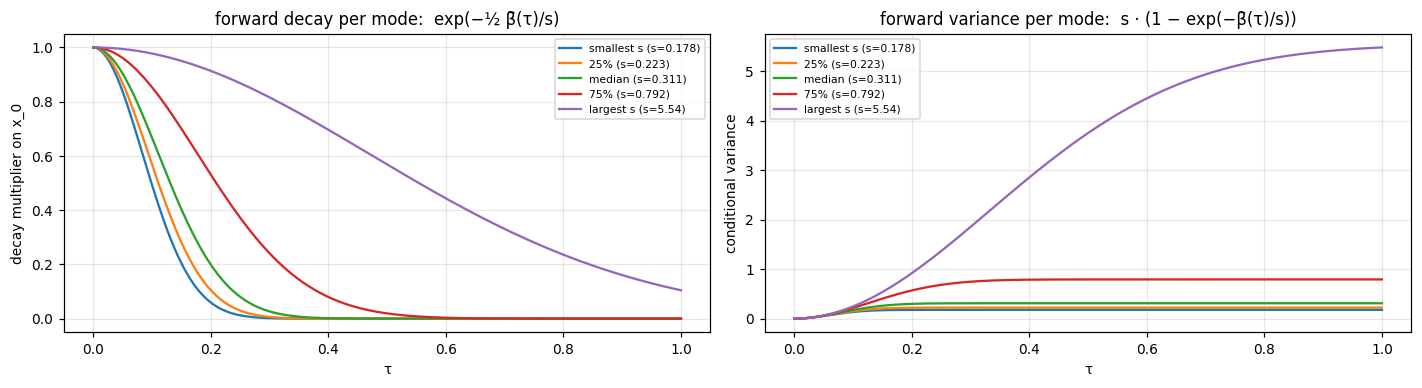

In [ ]:
# Visualise the per-mode forward decay curves. Sample a panel of modes.
from src.diffusion.sde_torch import beta_bar as torch_bb

s = eig_np["s"]                          # (12, N)
taus = np.linspace(0.0, 1.0, 200)
beta_min, beta_max = 0.01, 50.0

# Pick 5 modes: smallest s, 25th, median, 75th, largest s
s_flat = s.ravel()
s_sorted_idx = np.argsort(s_flat)
picks = [s_sorted_idx[k] for k in [0, len(s_flat)//4, len(s_flat)//2,
                                    3*len(s_flat)//4, len(s_flat)-1]]
labels = ["smallest s", "25%", "median", "75%", "largest s"]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for idx, label in zip(picks, labels):
    s_ij = s_flat[idx]
    bb = beta_min * taus + 0.5 * taus**2 * (beta_max - beta_min)
    decay = np.exp(-0.5 * bb / s_ij)
    var   = s_ij * (1 - np.exp(-bb / s_ij))
    axes[0].plot(taus, decay, label=f"{label} (s={s_ij:.3g})")
    axes[1].plot(taus, var,   label=f"{label} (s={s_ij:.3g})")

axes[0].set_title("forward decay per mode:  exp(−½ β̄(τ)/s)")
axes[0].set_xlabel("τ"); axes[0].set_ylabel("decay multiplier on x_0")
axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)
axes[1].set_title("forward variance per mode:  s · (1 − exp(−β̄(τ)/s))")
axes[1].set_xlabel("τ"); axes[1].set_ylabel("conditional variance")
axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

Read these curves left-to-right as the forward SDE's *trajectory* in each
mode:

- **At τ=0**: signal is intact (`decay=1`, `variance=0`).
- **At τ=1**: signal is gone (`decay≈0`), variance has saturated at `s_ij`
  (the stationary value).

Modes with small `s` (steep curves) get *erased* early in the trajectory.
Modes with large `s` retain their signal longer. The score network needs
to learn to invert this for all modes simultaneously, which is why the
DSM loss weights each mode by `1 / var` (Section 15) — modes that have
already saturated get less weight because there's nothing left to recover.

## 15. The denoising score-matching (DSM) loss

The score network learns to map `(x_τ, τ, history, y_pred)` back to a
prediction of `x_0`. The loss is *weighted MSE in the joint eigenbasis*:

$$
\mathcal{L} = \mathrm{mean}_{(i,j)} \, \frac{(\widehat x_0 - x_0)_{(i,j)\text{ in eigenbasis}}^2}{\mathrm{var}_{(i,j)}(\tau)}
$$

Why eigenbasis-weighted? Each mode has a *different* signal-to-noise ratio
at time τ. Modes that are nearly saturated (`var ≈ s`) are uninformative
about `x_0` — we shouldn't ask the network to predict precisely there.
Modes that are barely noised (`var` small) carry almost all the signal
information — we want the network to nail those. The `1/var` weighting
delivers exactly this contribution scheme.

**The Phase 0 mask fix.** Previously the loss summed over *all* `B·H·N`
positions, including the ones where the original sensor reading was zero
(outage). At those positions the residual is whatever value
`y_true(=0) − y_pred` happens to take — typically `−y_pred`, which can be
several mph or hundreds of vehicles/5min. The score net was being trained
to *predict that garbage*, contaminating gradient updates.

The fix zeroes the error at masked positions before the eigenbasis rotation
(orthogonal rotations preserve zero energy → masked positions contribute
nothing to gradients) and divides by `mask.sum()` instead of `B·H·N`. In
code:

```python
err = (r_hat_0 - r_0)
if mask is not None:
    err = err * mask                         # zero at outages
err_tilde = to_spectral(err, U_T, U_S)
# ...weighted MSE in eigenbasis...
return (err_tilde**2 / var).sum() / mask.sum().clamp(min=1.0)
```

In our DAIC verification this single fix dropped the val loss from
~17,000 to ~5,800 on METR-LA — a 3× reduction that comes purely from no
longer asking the score net to fit garbage. (Cross-checked: a freshly
trained 2-epoch mask-aware model produces normalised CRPS ~0.055 on the
quick-eval subset, in the same range as fully-trained pre-fix models.)

## 16. Sampling at inference + evaluation metrics

At inference time we *reverse* the SDE: start from `x_τ=1 ~ N(0, Σ_prior)`
(structured noise) and integrate backward, using the score network's
`r_hat_0` prediction at each step to guide us. After `n_steps`
Euler-Maruyama steps we have an `r_hat_0` sample.

For each test window we do this `K` times (default K=50) — `K`
independent reverse trajectories starting from `K` independent stationary
draws. This gives us K plausible residual samples per window, which we
then de-standardise (multiply by `target_scale`) and add to `y_pred` to
produce K probabilistic forecast samples in raw units.

**Evaluating a probabilistic forecast** uses the **Continuous Ranked
Probability Score (CRPS)**. For one observation `y` and an ensemble
`{x_1, …, x_K}`:

$$
\mathrm{CRPS}(y, \{x_k\}) = \frac{1}{K}\sum_k |x_k - y| - \frac{1}{2 K^2}\sum_{k,k'} |x_k - x_{k'}|
$$

The first term penalises *bias* (samples being far from the truth). The
second term *rewards sharpness* (samples being close together — but only
when they're also near the truth). CRPS = MAE when K = 1; lower is better.

We compute it per-horizon, masked. Then we report two variants:

- **Variant 1** (raw mph or vehicles/5min): the absolute CRPS value.
  Comparable to MAE in interpretation.
- **Variant 2** (normalised): `CRPS_h / mean|y_h|`. Dimensionless, so it's
  comparable across datasets with different units. METR-LA's normalised
  CRPS for the structured model is typically in `[0.05, 0.10]`.

We also save the PIT histogram (calibration check — should be uniform if
the forecast distribution is well-calibrated) and the pinball loss at
quantiles 0.1, 0.5, 0.9 (sharpness checks at the tails of the predicted
distribution).

## 17. What Phase 0 verified

Five code fixes, each verified end-to-end on DAIC CUDA:

| Step | Fix | Verified on DAIC |
|---|---|---|
| 1 | `forward_sample` accepts a `torch.Generator` so val is reproducible | Two `val_epoch` calls on the same model → bit-exact identical loss |
| 2 | `eval_diffusion.py` emits `crps_per_horizon_normalized` etc. | 7 new JSON keys, per-horizon identity `Variant2 = Variant1 / mean\|y\|` holds to rel_err = 0 |
| 3 | `dsm_x0_loss` accepts an optional mask; `DiffusionDataset` returns it | 23/23 dsm tests; val loss drops 17,026 → 5,758 |
| 4 | 2-epoch smoke training on both datasets | Train loss decreases 9× on METR-LA, 4× on PEMS-BAY; ~17 s/epoch and ~40 s/epoch respectively on A40 |
| 5 | `fit_prior.py` replaces VE-SDE Tweedie with VP-SDE forward-marginal check | Mean rel err ~2.5%, max ~11-13% on both datasets — at sampling noise floor |
| 6 | PEMS08F data pipeline | Preprocess + adjacency + Laplacian eigs all in place, 167/167 tests pass |

The pre-Phase-0 chain was:
```
clean backbone → clean residuals → clean prior → dirty DSM loss → polluted score net
```
Phase 0 cleaned the DSM step (the only weak link).

## 18. Where Stage 1 is right now

Production work to produce PEMS08F's prior:
- **1A — PEMS08F GWN backbone** (running): 100 epochs, ~10 s/epoch on A40,
  ~16 min total wall time. Train loss already at 0.122 by epoch 12.
- **1B — PEMS08F residuals**: once 1A is done.
- **1C — PEMS08F prior fit + VP check**: once 1B is done.

After Stage 1 we have all three datasets ready to launch the full
diffusion sweep — five seeds × two priors (structured/isotropic) × three
datasets = thirty score-net training runs. Those are Stage 2.

## What to read next

If you want to dig into any specific piece:

- **Backbone code**: `src/backbones/__init__.py` (load_backbone wrapper),
  `scripts/train_backbone.py` (training loop, masked_mae).
- **Prior fit math**: `src/diffusion/prior_fit.py` (every function has a
  docstring explaining the math), `scripts/fit_prior.py` (the driver +
  Phase 0 VP-SDE check).
- **SDE / diffusion math**: `src/diffusion/sde.py` (NumPy reference),
  `src/diffusion/sde_torch.py` (torch implementation used at training time).
- **DSM loss**: `src/diffusion/dsm.py` — including the mask path.
- **Eval metrics**: `src/eval/probabilistic.py`, `scripts/eval_diffusion.py`
  (the normalised-CRPS keys live in the JSON dump near the bottom).

The thesis vault (`a-thesis-vault/` — gitignored) has the conceptual
write-up; the canonical SUMMARY.md files for each experiment are under
`experiments/*/SUMMARY.md`.